In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn

In [53]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_curve, auc, recall_score, confusion_matrix, ConfusionMatrixDisplay
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from lightgbm import LGBMClassifier

In [36]:
airports = pd.read_csv("airports.csv")
flights = pd.read_csv("flights.csv")
planes = pd.read_csv("planes.csv")
weather = pd.read_csv("weather.csv")

In [37]:
data = (
    flights
    .merge(planes, left_on="tailnum", right_on="tailnum", how="left")
    .merge(airports, left_on="origin", right_on="faa", how="left", suffixes=("_origin", "_dest"))
    .merge(airports, left_on="dest", right_on="faa", how="left", suffixes=("_origin", "_dest"))
    .merge(airports, left_on="dest", right_on="faa", how="left", suffixes=("_origin", "_dest"))
)   
data.to_csv("data.csv", index=False)

In [38]:
# Merge data with weather information at origin
data_with_weather = data.merge(
    weather, 
    left_on=["origin", "year_x", "month", "day", "hour"], 
    right_on=["origin", "year", "month", "day", "hour"],
    how="left",
    suffixes=("", "_weather_origin")
)

# Rename weather columns for clarity
data_with_weather = data_with_weather.rename(columns={
    "temp": "temp_origin",
    "dewp": "dewp_origin",
    "humid": "humid_origin",
    "wind_dir": "wind_dir_origin",
    "wind_speed": "wind_speed_origin",
    "wind_gust": "wind_gust_origin",
    "precip": "precip_origin",
    "pressure": "pressure_origin",
    "visib": "visib_origin"
})

# Drop duplicate time_hour column from weather merge
data_with_weather = data_with_weather.drop(columns=["time_hour_weather_origin", "year", "origin_weather_origin"], errors="ignore")

,year_x,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,...,tzone,temp_origin,dewp_origin,humid_origin,wind_dir_origin,wind_speed_origin,wind_gust_origin,precip_origin,pressure_origin,visib_origin
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,...,America/Chicago,39.02,28.04,64.43,260.0,12.65858,NaN,0.0,1011.9,10.0
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,...,America/Chicago,39.92,24.98,54.81,250.0,14.96014,21.86482,0.0,1011.4,10.0
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,...,America/New_York,39.02,26.96,61.63,260.0,14.96014,NaN,0.0,1012.1,10.0
3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,...,NaN,39.02,26.96,61.63,260.0,14.96014,NaN,0.0,1012.1,10.0
4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,...,America/New_York,39.92,24.98,54.81,260.0,16.11092,23.01560,0.0,1011.7,10.0


In [39]:
data_with_weather.info()

<class 'pandas.DataFrame'>
RangeIndex: 336776 entries, 0 to 336775
Data columns (total 60 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   year_x             336776 non-null  int64  
 1   month              336776 non-null  int64  
 2   day                336776 non-null  int64  
 3   dep_time           328521 non-null  float64
 4   sched_dep_time     336776 non-null  int64  
 5   dep_delay          328521 non-null  float64
 6   arr_time           328063 non-null  float64
 7   sched_arr_time     336776 non-null  int64  
 8   arr_delay          327346 non-null  float64
 9   carrier            336776 non-null  str    
 10  flight             336776 non-null  int64  
 11  tailnum            334264 non-null  str    
 12  origin             336776 non-null  str    
 13  dest               336776 non-null  str    
 14  air_time           327346 non-null  float64
 15  distance           336776 non-null  int64  
 16  hour         

In [40]:
# Remove speed and wind_gust columns, then drop all null values
data_with_weather = data_with_weather.drop(columns=['speed', 'wind_gust_origin','wind_gust_dest','air_time',"arr_time"], errors='ignore')
data_with_weather = data_with_weather.dropna()

In [41]:
# add binary delay flag: 1 if arrival delay > 15 minutes, else 0
data_with_weather['delay_binary'] = (data_with_weather['arr_delay'] > 15).astype(int)
data_with_weather = data_with_weather.drop(columns=['arr_delay'], errors='ignore')

,year_x,month,day,dep_time,sched_dep_time,dep_delay,sched_arr_time,carrier,flight,tailnum,...,tzone,temp_origin,dewp_origin,humid_origin,wind_dir_origin,wind_speed_origin,precip_origin,pressure_origin,visib_origin,delay_binary
0,2013,1,1,517.0,515,2.0,819,UA,1545,N14228,...,America/Chicago,39.02,28.04,64.43,260.0,12.65858,0.0,1011.9,10.0,0
1,2013,1,1,533.0,529,4.0,830,UA,1714,N24211,...,America/Chicago,39.92,24.98,54.81,250.0,14.96014,0.0,1011.4,10.0,1
2,2013,1,1,542.0,540,2.0,850,AA,1141,N619AA,...,America/New_York,39.02,26.96,61.63,260.0,14.96014,0.0,1012.1,10.0,1
4,2013,1,1,554.0,600,-6.0,837,DL,461,N668DN,...,America/New_York,39.92,24.98,54.81,260.0,16.11092,0.0,1011.7,10.0,0
5,2013,1,1,554.0,558,-4.0,728,UA,1696,N39463,...,America/Chicago,39.02,28.04,64.43,260.0,12.65858,0.0,1011.9,10.0,0


In [42]:
# prepare features and target
X = data_with_weather.drop(columns=['delay_binary'])
y = data_with_weather['delay_binary']

# prepare numeric features and target, then do stratified train/test split
numeric_cols = data_with_weather.select_dtypes(include=[np.number]).columns.tolist()
if 'delay_binary' in numeric_cols:
    numeric_cols.remove('delay_binary')

X = data_with_weather[numeric_cols]
y = data_with_weather['delay_binary']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train:", X_train.shape, "X_test:", X_test.shape, "y_train:", y_train.shape, "y_test:", y_test.shape)
X_train.head()

X_train: (185929, 34) X_test: (46483, 34) y_train: (185929,) y_test: (46483,)


,year_x,month,day,dep_time,sched_dep_time,dep_delay,sched_arr_time,flight,distance,hour,...,alt,tz,temp_origin,dewp_origin,humid_origin,wind_dir_origin,wind_speed_origin,precip_origin,pressure_origin,visib_origin
256369,2013,7,7,1737.0,1742,-5.0,1908,1248,200,17,...,19.0,-5.0,93.92,69.98,45.92,240.0,17.26170,0.00,1013.4,10.0
103380,2013,12,22,2052.0,1829,143.0,2124,543,1023,18,...,19.0,-5.0,64.94,55.94,72.62,250.0,9.20624,0.00,1012.8,10.0
286637,2013,8,8,552.0,600,-8.0,712,5716,228,6,...,313.0,-5.0,71.96,69.08,90.66,180.0,13.80936,0.08,1018.2,10.0
240693,2013,6,20,1643.0,1633,10.0,1916,1178,1400,16,...,97.0,-6.0,78.08,55.04,45.00,160.0,6.90468,0.00,1023.3,10.0
102137,2013,12,21,1249.0,1245,4.0,1446,1131,502,12,...,645.0,-5.0,57.92,46.04,64.52,230.0,14.96014,0.00,1013.1,10.0


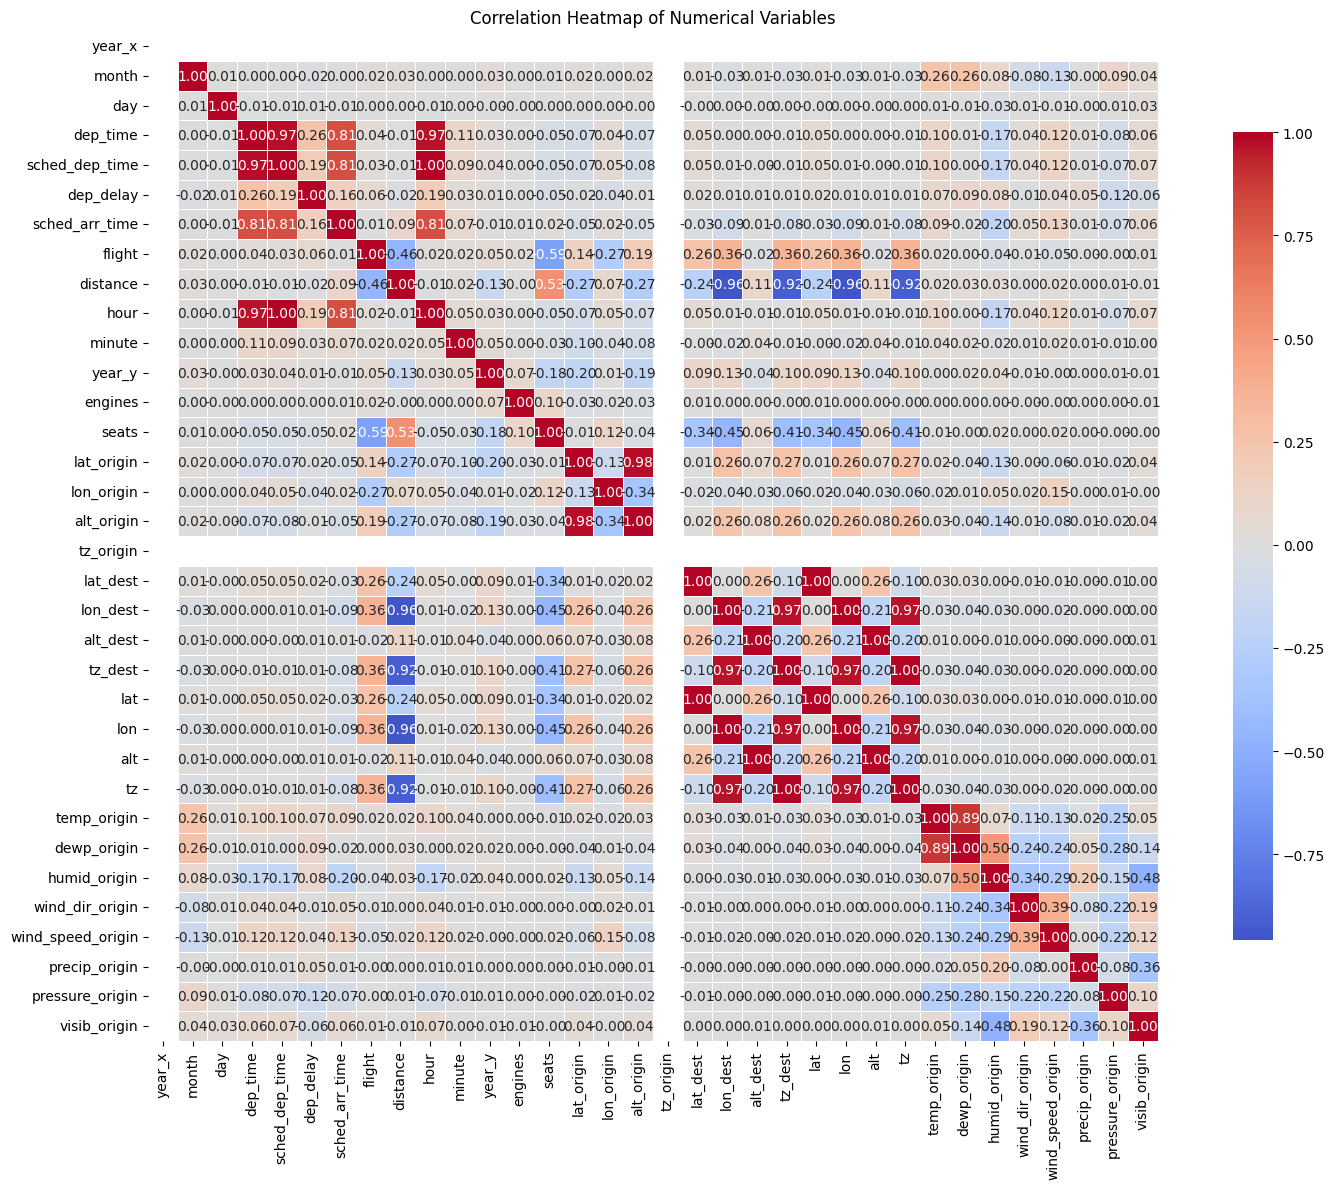

In [59]:
# Create a correlation heatmap of numerical variables
correlation_matrix = X_train.corr()

plt.figure(figsize=(16, 12))
sn.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
           square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

In [45]:
# pipeline with scaler + XGBoost
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ('clf', XGBClassifier(objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1))
])

In [46]:
# Define parameter distributions for RandomizedSearchCV
param_dist = {
    'clf__n_estimators': [100, 200, 300, 400, 500],
    'clf__max_depth': [3, 5, 7, 9, 11, 15],
    'clf__learning_rate': [0.01, 0.05, 0.1, 0.15, 0.2],
    'clf__subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'clf__colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'clf__min_child_weight': [1, 3, 5, 7],
    'clf__gamma': [0, 0.1, 0.5, 1, 2],
    'clf__reg_alpha': [0, 0.1, 0.5, 1, 2],
    'clf__reg_lambda': [0.5, 1, 1.5, 2],
}

# Perform RandomizedSearchCV with extensive search
random_search = RandomizedSearchCV(
    pipeline,
    param_distributions=param_dist,
    n_iter=100,  # Number of parameter settings to sample
    cv=5,  # 5-fold cross-validation
    scoring='f1',
    n_jobs=-1,
    random_state=42,
    verbose=2
)

# Fit the model
random_search.fit(X_train, y_train)

# Print results
print("Best parameters:", random_search.best_params_)
print("Best cross-validation score:", random_search.best_score_)

# Evaluate on test set
y_pred = random_search.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)
print("Test set accuracy:", test_accuracy)
  
# Display top 10 parameter combinations
results_df = pd.DataFrame(random_search.cv_results_).sort_values('rank_test_score')
print("\nTop 10 parameter combinations:")
print(results_df[['param_clf__n_estimators', 'param_clf__max_depth', 'param_clf__learning_rate', 'mean_test_score', 'rank_test_score']].head(10))

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best parameters: {'clf__subsample': 0.7, 'clf__reg_lambda': 2, 'clf__reg_alpha': 2, 'clf__n_estimators': 400, 'clf__min_child_weight': 5, 'clf__max_depth': 11, 'clf__learning_rate': 0.1, 'clf__gamma': 1, 'clf__colsample_bytree': 0.9}
Best cross-validation score: 0.8055743157751332
Test set accuracy: 0.9220360131661037

Top 10 parameter combinations:
    param_clf__n_estimators  param_clf__max_depth  param_clf__learning_rate  \
17                      400                    11                      0.10   
93                      300                    15                      0.15   
28                      500                     9                      0.10   
7                       500                    15                      0.05   
78                      500                    11                      0.05   
12                      300                     9                      0.20   
82                      300     

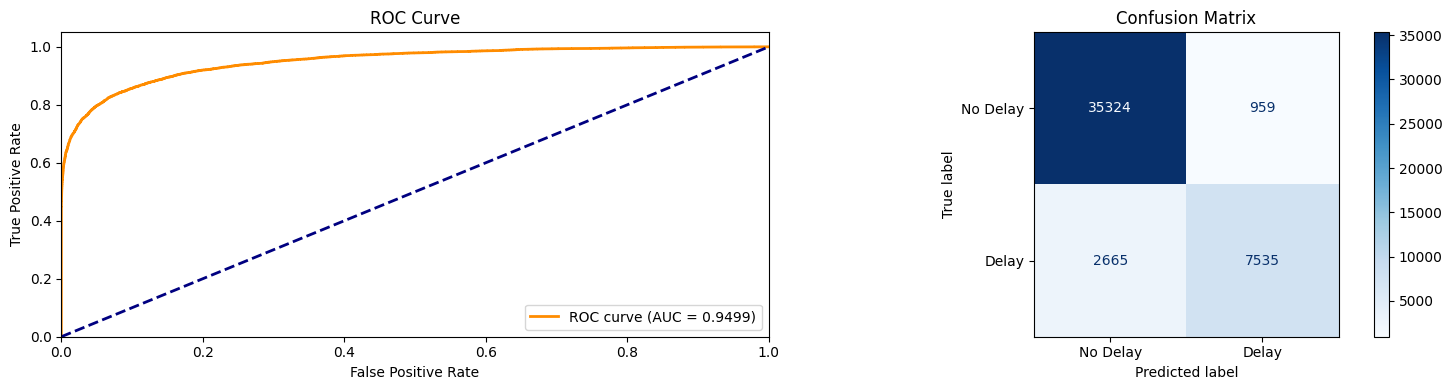

Recall: 0.7387
ROC AUC: 0.9499
f1 Score: 0.8203
Test Accuracy: 0.9220


In [73]:
# Calculate ROC curve
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, random_search.predict_proba(X_test)[:, 1])
roc_auc = auc(xgb_fpr, xgb_tpr)

# Calculate recall
recall = recall_score(y_test, y_pred)

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Plot ROC Curve
axes[0].plot(xgb_fpr, xgb_tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve')
axes[0].legend(loc="lower right")


# Plot Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Delay', 'Delay'])
disp.plot(ax=axes[1], cmap='Blues')
axes[1].set_title('Confusion Matrix')
xgb_f1 = 2 * (recall * test_accuracy) / (recall + test_accuracy) if (recall + test_accuracy) > 0 else 0
plt.tight_layout()
plt.show()

print(f"Recall: {recall:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")
print(f"f1 Score: {xgb_f1:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

In [49]:

rf_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ('clf', RandomForestClassifier(random_state=42, n_jobs=-1))
])

# Define parameter distributions for Random Forest
rf_param_dist = {
    'clf__n_estimators': [100, 200, 300, 400, 500],
    'clf__max_depth': [10, 15, 20, 25, 30],
    'clf__min_samples_split': [2, 5, 10],
    'clf__min_samples_leaf': [1, 2, 4],
    'clf__max_features': ['sqrt', 'log2'],
    'clf__bootstrap': [True, False],
}

# Perform RandomizedSearchCV
rf_random_search = RandomizedSearchCV(
    rf_pipeline,
    param_distributions=rf_param_dist,
    n_iter=100,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    random_state=42,
    verbose=2
)

# Fit the model
rf_random_search.fit(X_train, y_train)

# Print results
print("Best parameters:", rf_random_search.best_params_)
print("Best cross-validation score:", rf_random_search.best_score_)

# Evaluate on test set
rf_y_pred = rf_random_search.predict(X_test)
rf_test_accuracy = accuracy_score(y_test, rf_y_pred)
print("Test set accuracy:", rf_test_accuracy)

# Display top 10 parameter combinations
rf_results_df = pd.DataFrame(rf_random_search.cv_results_).sort_values('rank_test_score')
print("\nTop 10 parameter combinations:")
print(rf_results_df[['param_clf__n_estimators', 'param_clf__max_depth', 'param_clf__min_samples_split', 'mean_test_score', 'rank_test_score']].head(10))

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best parameters: {'clf__n_estimators': 300, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 'clf__max_features': 'sqrt', 'clf__max_depth': 30, 'clf__bootstrap': False}
Best cross-validation score: 0.7884971580658137
Test set accuracy: 0.91052642901706

Top 10 parameter combinations:
    param_clf__n_estimators  param_clf__max_depth  \
49                      300                    30   
1                       300                    30   
43                      500                    25   
72                      200                    30   
84                      100                    30   
62                      500                    25   
27                      300                    30   
21                      200                    25   
94                      400                    25   
75                      400                    30   

    param_clf__min_samples_split  mean_test_score  rank_test

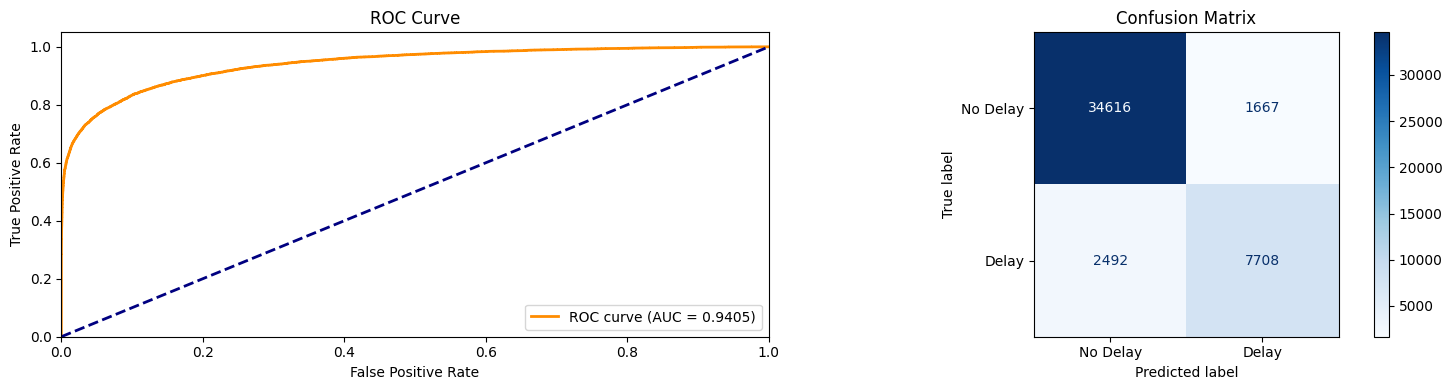

Recall: 0.7557
ROC AUC: 0.9405
f1 Score: 0.8259
Test Accuracy: 0.9105


In [72]:
# Calculate ROC curve
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_random_search.predict_proba(X_test)[:, 1])
rf_roc_auc = auc(rf_fpr, rf_tpr)

# Calculate recall
rf_recall = recall_score(y_test, rf_y_pred)

# Calculate confusion matrix
rf_cm = confusion_matrix(y_test, rf_y_pred)

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Plot ROC Curve
axes[0].plot(rf_fpr, rf_tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {rf_roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve')
axes[0].legend(loc="lower right")


# Plot Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=rf_cm, display_labels=['No Delay', 'Delay'])
disp.plot(ax=axes[1], cmap='Blues')
axes[1].set_title('Confusion Matrix')
rf_f1 = 2 * (rf_recall * rf_test_accuracy) / (rf_recall + rf_test_accuracy) if (rf_recall + rf_test_accuracy) > 0 else 0
plt.tight_layout()
plt.show()

print(f"Recall: {rf_recall:.4f}")
print(f"ROC AUC: {rf_roc_auc:.4f}")
print(f"f1 Score: {rf_f1:.4f}")
print(f"Test Accuracy: {rf_test_accuracy:.4f}")

In [54]:
# Create LightGBM pipeline
lgb_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ('clf', LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1))
])

# Define parameter distributions for LightGBM
lgb_param_dist = {
    'clf__n_estimators': [100, 200, 300, 400, 500],
    'clf__max_depth': [5, 10, 15, 20, 25],
    'clf__learning_rate': [0.01, 0.05, 0.1, 0.15, 0.2],
    'clf__num_leaves': [20, 31, 50, 70, 100],
    'clf__min_child_samples': [10, 20, 30, 40],
    'clf__subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'clf__colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'clf__reg_alpha': [0, 0.1, 0.5, 1, 2],
    'clf__reg_lambda': [0.5, 1, 1.5, 2],
}

# Perform RandomizedSearchCV
lgb_random_search = RandomizedSearchCV(
    lgb_pipeline,
    param_distributions=lgb_param_dist,
    n_iter=100,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    random_state=42,
    verbose=2
)

# Fit the model
lgb_random_search.fit(X_train, y_train)

# Print results
print("Best parameters:", lgb_random_search.best_params_)
print("Best cross-validation score:", lgb_random_search.best_score_)

# Evaluate on test set
lgb_y_pred = lgb_random_search.predict(X_test)
lgb_test_accuracy = accuracy_score(y_test, lgb_y_pred)
print("Test set accuracy:", lgb_test_accuracy)

# Display top 10 parameter combinations
lgb_results_df = pd.DataFrame(lgb_random_search.cv_results_).sort_values('rank_test_score')
print("\nTop 10 parameter combinations:")
print(lgb_results_df[['param_clf__n_estimators', 'param_clf__max_depth', 'param_clf__learning_rate', 'mean_test_score', 'rank_test_score']].head(10))

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best parameters: {'clf__subsample': 0.9, 'clf__reg_lambda': 1.5, 'clf__reg_alpha': 0, 'clf__num_leaves': 100, 'clf__n_estimators': 500, 'clf__min_child_samples': 40, 'clf__max_depth': 20, 'clf__learning_rate': 0.2, 'clf__colsample_bytree': 0.9}
Best cross-validation score: 0.8044552461270887


C:\Users\timot\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Test set accuracy: 0.9207021921992987

Top 10 parameter combinations:
    param_clf__n_estimators  param_clf__max_depth  param_clf__learning_rate  \
62                      500                    20                      0.20   
42                      400                    20                      0.20   
8                       500                    25                      0.20   
78                      500                    20                      0.15   
12                      500                    20                      0.20   
54                      400                    25                      0.10   
22                      500                    20                      0.15   
23                      400                    20                      0.20   
0                       400                    15                      0.10   
50                      300                    15                      0.15   

    mean_test_score  rank_test_score  
62         0.804455  

C:\Users\timot\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


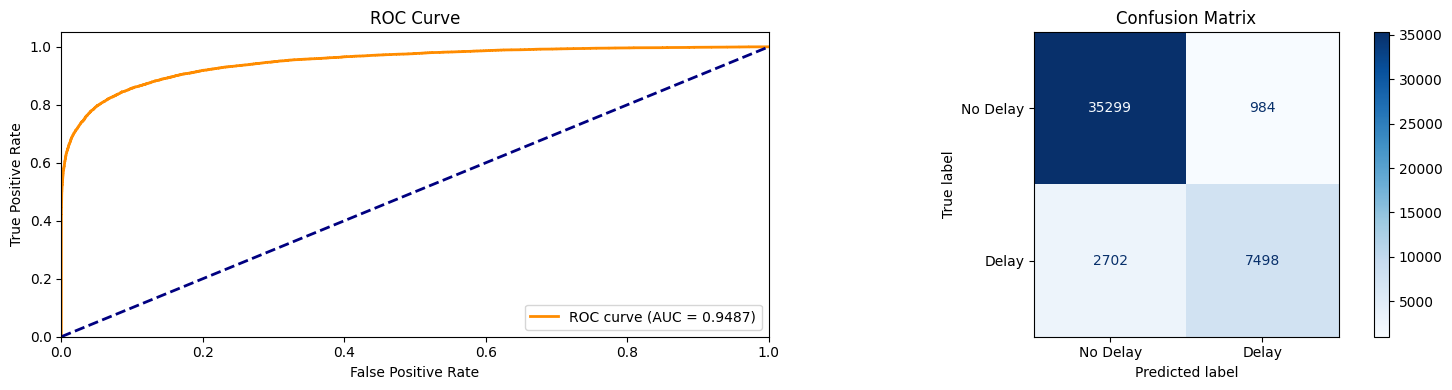

Recall: 0.7351
ROC AUC: 0.9487
f1 Score: 0.8175
Test Accuracy: 0.9207


In [71]:
# Calculate ROC curve
lgb_fpr, lgb_tpr, _ = roc_curve(y_test, lgb_random_search.predict_proba(X_test)[:, 1])
lgb_roc_auc = auc(lgb_fpr, lgb_tpr)

# Calculate recall
lgb_recall = recall_score(y_test, lgb_y_pred)

# Calculate confusion matrix
lgb_cm = confusion_matrix(y_test, lgb_y_pred)

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Plot ROC Curve
axes[0].plot(lgb_fpr, lgb_tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {lgb_roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve')
axes[0].legend(loc="lower right")


# Plot Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=lgb_cm, display_labels=['No Delay', 'Delay'])
disp.plot(ax=axes[1], cmap='Blues')
axes[1].set_title('Confusion Matrix')
lgb_f1 = 2 * (lgb_recall * lgb_test_accuracy) / (lgb_recall + lgb_test_accuracy) if (lgb_recall + lgb_test_accuracy) > 0 else 0
plt.tight_layout()
plt.show()

print(f"Recall: {lgb_recall:.4f}")
print(f"ROC AUC: {lgb_roc_auc:.4f}")
print(f"f1 Score: {lgb_f1:.4f}")
print(f"Test Accuracy: {lgb_test_accuracy:.4f}")

XGBoost ROC AUC: 0.9499, Weight: 0.3346
Random Forest ROC AUC: 0.9405, Weight: 0.3313
LightGBM ROC AUC: 0.9487, Weight: 0.3342


C:\Users\timot\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Ensemble Model Performance:
Accuracy: 0.9217
Recall: 0.7413
ROC AUC: 0.9500
F1 Score: 0.8217


C:\Users\timot\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


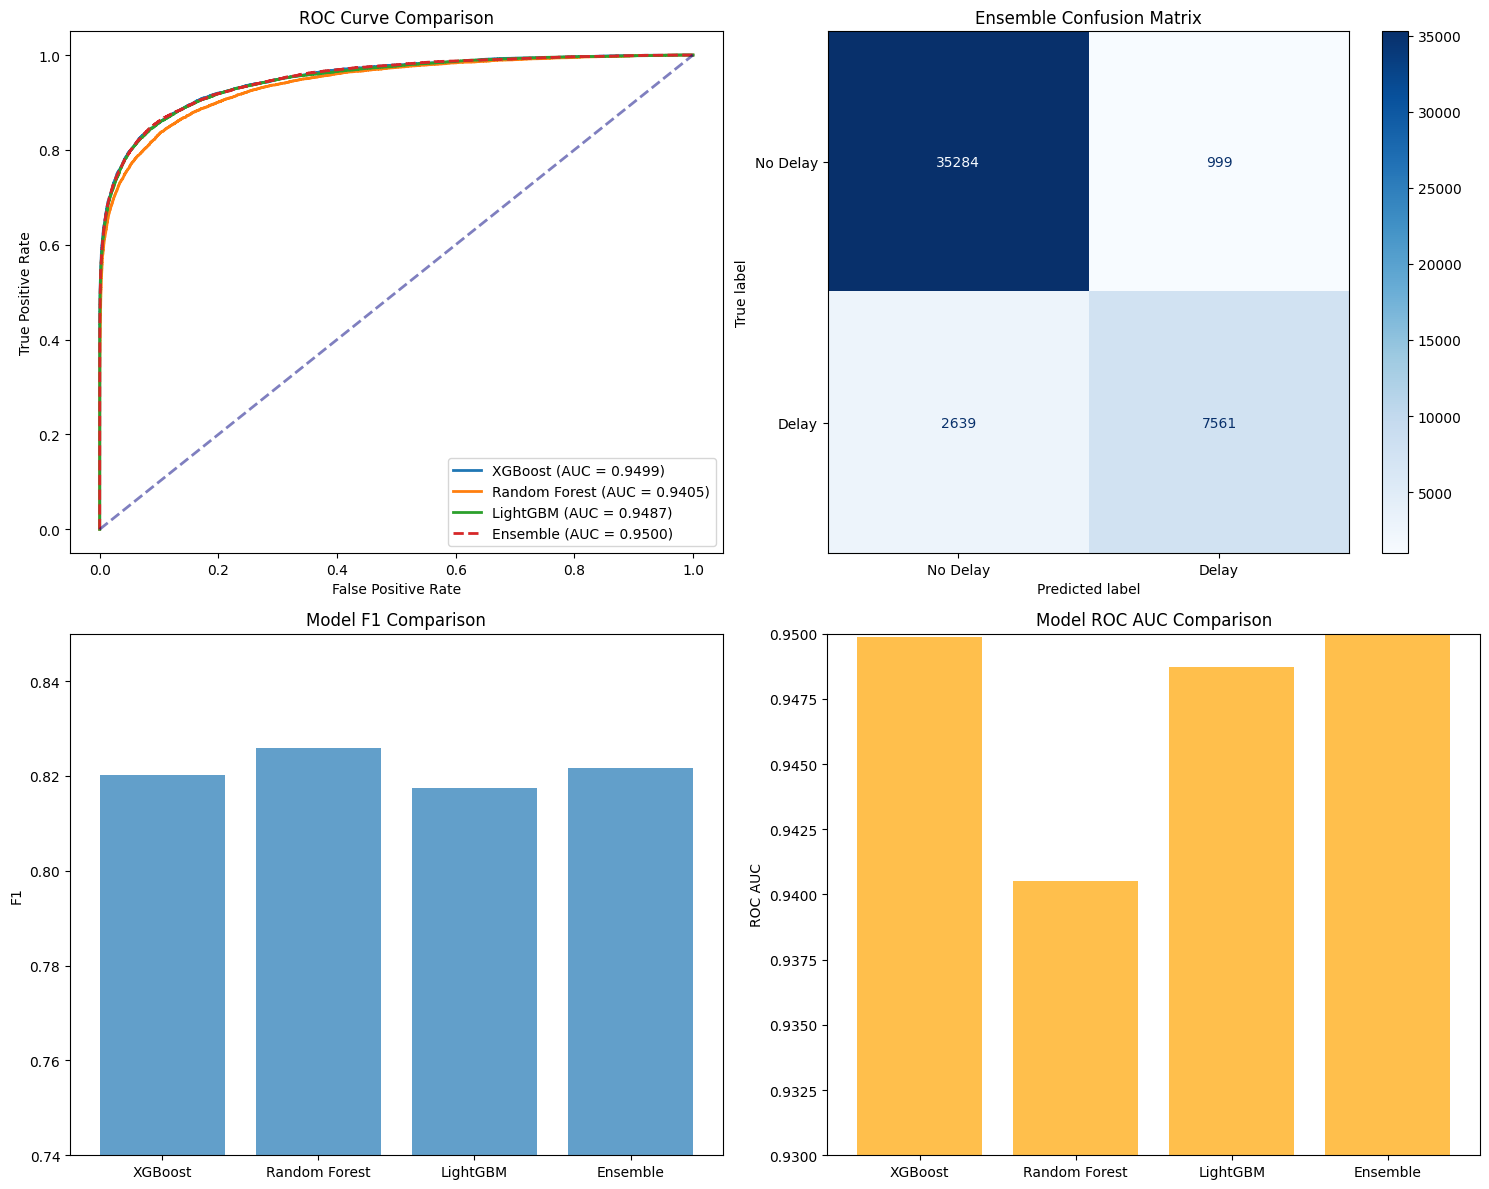


Weights used in ensemble:
XGBoost: 0.3346
Random Forest: 0.3313
LightGBM: 0.3342


In [74]:

# Calculate weights proportional to ROC AUC scores
total_auc = roc_auc + rf_roc_auc + lgb_roc_auc
w_xgb = roc_auc / total_auc
w_rf = rf_roc_auc / total_auc
w_lgb = lgb_roc_auc / total_auc

print(f"XGBoost ROC AUC: {roc_auc:.4f}, Weight: {w_xgb:.4f}")
print(f"Random Forest ROC AUC: {rf_roc_auc:.4f}, Weight: {w_rf:.4f}")
print(f"LightGBM ROC AUC: {lgb_roc_auc:.4f}, Weight: {w_lgb:.4f}")

# Get probability predictions from all three models
xgb_proba = random_search.predict_proba(X_test)[:, 1]
rf_proba = rf_random_search.predict_proba(X_test)[:, 1]
lgb_proba = lgb_random_search.predict_proba(X_test)[:, 1]

# Weighted average ensemble prediction
ensemble_proba = (w_xgb * xgb_proba + w_rf * rf_proba + w_lgb * lgb_proba)
ensemble_pred = (ensemble_proba > 0.5).astype(int)

# Evaluate ensemble model
ensemble_accuracy = accuracy_score(y_test, ensemble_pred)
ensemble_recall = recall_score(y_test, ensemble_pred)
fpr_ens, tpr_ens, _ = roc_curve(y_test, ensemble_proba)
ensemble_roc_auc = auc(fpr_ens, tpr_ens)
ensemble_cm = confusion_matrix(y_test, ensemble_pred)

print(f"\nEnsemble Model Performance:")
print(f"Accuracy: {ensemble_accuracy:.4f}")
print(f"Recall: {ensemble_recall:.4f}")
print(f"ROC AUC: {ensemble_roc_auc:.4f}")
print(f"F1 Score: {(2 * ensemble_recall * ensemble_accuracy) / (ensemble_recall + ensemble_accuracy):.4f}")
# Plot comparison
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# ROC Curves comparison
axes[0, 0].plot(xgb_fpr, xgb_tpr, label=f'XGBoost (AUC = {roc_auc:.4f})', lw=2)
axes[0, 0].plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {rf_roc_auc:.4f})', lw=2)
axes[0, 0].plot(lgb_fpr, lgb_tpr, label=f'LightGBM (AUC = {lgb_roc_auc:.4f})', lw=2)
axes[0, 0].plot(fpr_ens, tpr_ens, label=f'Ensemble (AUC = {ensemble_roc_auc:.4f})', lw=2, linestyle='--')
axes[0, 0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', alpha=0.5)
axes[0, 0].set_xlabel('False Positive Rate')
axes[0, 0].set_ylabel('True Positive Rate')
axes[0, 0].set_title('ROC Curve Comparison')
axes[0, 0].legend(loc="lower right")

# Ensemble Confusion Matrix
disp_ens = ConfusionMatrixDisplay(confusion_matrix=ensemble_cm, display_labels=['No Delay', 'Delay'])
disp_ens.plot(ax=axes[0, 1], cmap='Blues')
axes[0, 1].set_title('Ensemble Confusion Matrix')

# Model Comparison Bar Chart
models = ['XGBoost', 'Random Forest', 'LightGBM', 'Ensemble']
accuracies = [test_accuracy, rf_test_accuracy, lgb_test_accuracy, ensemble_accuracy]
auc_scores = [roc_auc, rf_roc_auc, lgb_roc_auc, ensemble_roc_auc]
test_recalls = [recall_score(y_test, random_search.predict(X_test)),
                recall_score(y_test, rf_random_search.predict(X_test)),
                recall_score(y_test, lgb_random_search.predict(X_test)),
                ensemble_recall]

f1_scores = [
    xgb_f1,
    rf_f1,
    lgb_f1,
    2 * (ensemble_accuracy * ensemble_recall) / (ensemble_accuracy + ensemble_recall) if (ensemble_accuracy + ensemble_recall) > 0 else 0
]


axes[1, 0].bar(models, f1_scores, alpha=0.7)
axes[1, 0].set_ylabel('F1')
axes[1, 0].set_title('Model F1 Comparison')
axes[1, 0].set_ylim([0.74, 0.85])

axes[1, 1].bar(models, auc_scores, alpha=0.7, color='orange')
axes[1, 1].set_ylabel('ROC AUC')
axes[1, 1].set_title('Model ROC AUC Comparison')
axes[1, 1].set_ylim([0.93, 0.95])

plt.tight_layout()
plt.show()

print(f"\nWeights used in ensemble:")
print(f"XGBoost: {w_xgb:.4f}")
print(f"Random Forest: {w_rf:.4f}")
print(f"LightGBM: {w_lgb:.4f}")

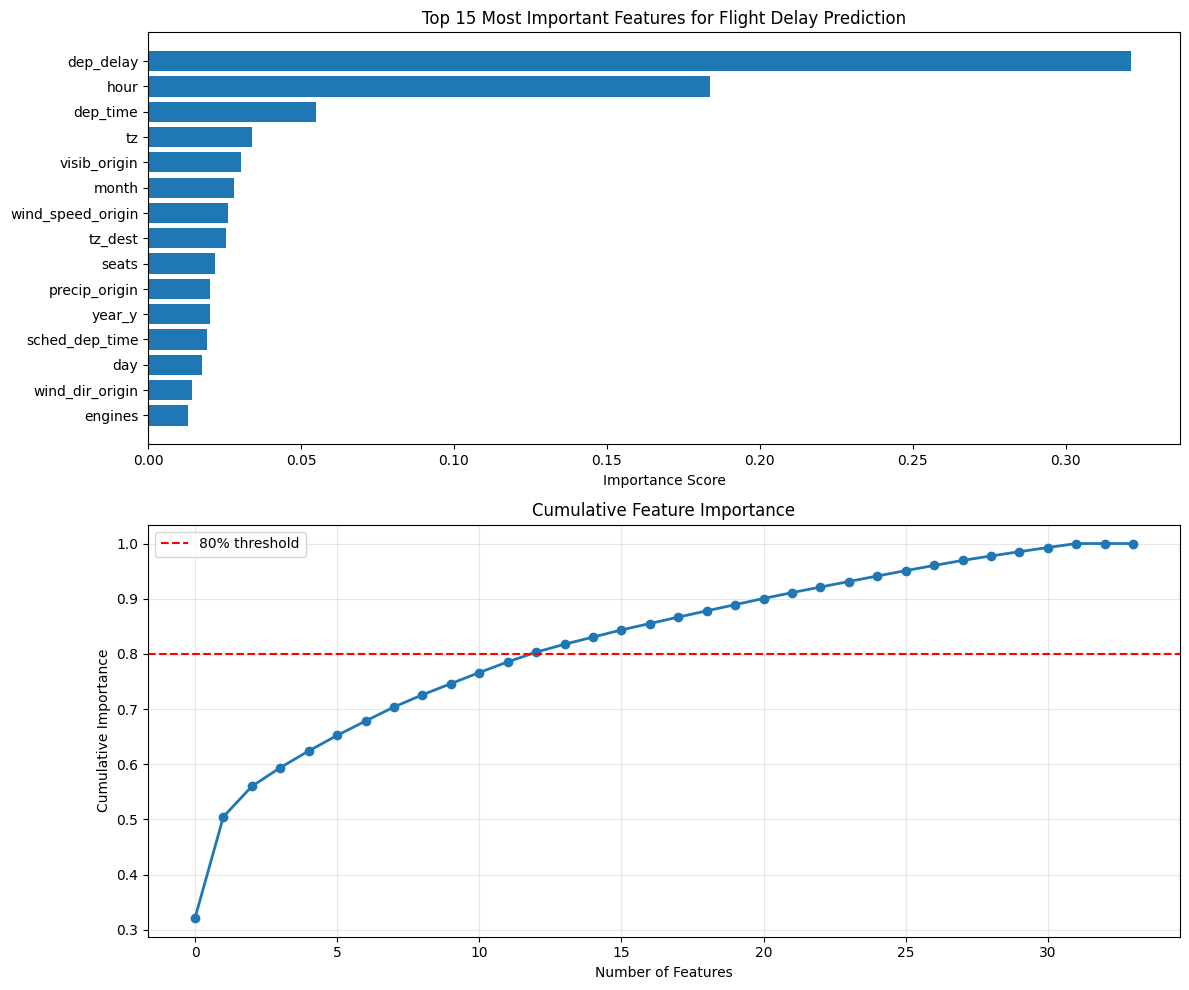


Top 15 Most Important Features:
              feature  importance
5           dep_delay    0.321280
9                hour    0.183625
3            dep_time    0.055014
25                 tz    0.033917
33       visib_origin    0.030271
1               month    0.028123
30  wind_speed_origin    0.026053
21            tz_dest    0.025518
13              seats    0.022005
31      precip_origin    0.020265
11             year_y    0.020163
4      sched_dep_time    0.019256
2                 day    0.017644
29    wind_dir_origin    0.014349
12            engines    0.012987


In [75]:
# Get feature importance from the XGBoost model
xgb_model = random_search.best_estimator_.named_steps['clf']
feature_importance = xgb_model.feature_importances_
feature_names = X_train.columns

# Create a dataframe with feature importance
importance_df = pd.DataFrame({
	'feature': feature_names,
	'importance': feature_importance
}).sort_values('importance', ascending=False)

# Plot top 15 most important features
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Bar plot of top 15 features
top_15 = importance_df.head(15)
axes[0].barh(range(len(top_15)), top_15['importance'].values)
axes[0].set_yticks(range(len(top_15)))
axes[0].set_yticklabels(top_15['feature'].values)
axes[0].set_xlabel('Importance Score')
axes[0].set_title('Top 15 Most Important Features for Flight Delay Prediction')
axes[0].invert_yaxis()

# Cumulative importance plot
cumulative_importance = importance_df['importance'].cumsum() / importance_df['importance'].sum()
axes[1].plot(range(len(cumulative_importance)), cumulative_importance.values, marker='o', linestyle='-', linewidth=2)
axes[1].axhline(y=0.8, color='r', linestyle='--', label='80% threshold')
axes[1].set_xlabel('Number of Features')
axes[1].set_ylabel('Cumulative Importance')
axes[1].set_title('Cumulative Feature Importance')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nTop 15 Most Important Features:")
print(top_15)